In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import xgboost; print(xgboost.__version__)

1.7.4


In [3]:
pd.set_option('display.max_columns', None)
pd.set_option('max_colwidth', None)

In [4]:
dataset = pd.read_csv ('train_data.txt', delimiter=",", header=0, index_col = [0], 
                        names=['id',
                               'Jitter_local','Jitter_local_absolute','Jitter_rap','Jitter_ppq5','Jitter_ddp',
                               'Shimmer_local','Shimmer_local_dB','Shimmer_apq3','Shimmer_apq5', 'Shimmer_apq11','Shimmer_dda', 
                               'AC','NTH','HTN', 
                               'Median_pitch','Mean_pitch','Standard_deviation','Minimum_pitch','Maximum_pitch',
                               'Number_of_pulses','Number_of_periods','Mean_period','Standard_deviation_of_period',
                               'Fraction_of_locally_unvoiced_frames','Number_of_voice_breaks','Degree_of_voice_breaks',
                               'UPDRS', 
                               'class_information']) 

dataset.head()

,Jitter_local,Jitter_local_absolute,Jitter_rap,Jitter_ppq5,Jitter_ddp,Shimmer_local,Shimmer_local_dB,Shimmer_apq3,Shimmer_apq5,Shimmer_apq11,Shimmer_dda,AC,NTH,HTN,Median_pitch,Mean_pitch,Standard_deviation,Minimum_pitch,Maximum_pitch,Number_of_pulses,Number_of_periods,Mean_period,Standard_deviation_of_period,Fraction_of_locally_unvoiced_frames,Number_of_voice_breaks,Degree_of_voice_breaks,UPDRS,class_information
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,1.488,0.000090,0.900,0.794,2.699,8.334,0.779,4.517,4.609,6.802,13.551,0.905905,0.119116,11.130,166.533,164.781,10.421,142.229,187.576,160.0,159.0,0.006065,0.000416,0.000,0.0,0.000,23,1.0
1,0.728,0.000038,0.353,0.376,1.059,5.864,0.642,2.058,3.180,7.194,6.175,0.951285,0.066758,17.403,195.252,193.289,14.773,159.515,234.505,170.0,169.0,0.005181,0.000403,2.247,0.0,0.000,23,1.0
1,1.220,0.000074,0.732,0.670,2.196,8.719,0.875,4.347,5.166,7.548,13.040,0.911508,0.109983,12.212,158.689,164.768,12.981,146.445,211.442,1431.0,1427.0,0.006071,0.000474,10.656,1.0,0.178,23,1.0
1,2.502,0.000123,1.156,1.634,3.469,13.513,1.273,5.263,8.771,16.779,15.789,0.901302,0.121982,11.384,201.997,203.471,10.853,182.713,220.230,94.0,92.0,0.004910,0.000320,0.000,0.0,0.000,23,1.0
1,3.509,0.000167,1.715,1.539,5.145,9.112,1.040,3.102,4.927,12.823,9.307,0.856907,0.236831,10.653,211.887,208.440,11.499,182.821,225.162,117.0,114.0,0.004757,0.000380,18.182,1.0,13.318,23,1.0


In [48]:
df_test = pd.read_csv ('youtube_data.txt', delimiter=",", header=0, index_col = [0], 
                        names=['id',
                               'Jitter_local','Jitter_local_absolute','Jitter_rap','Jitter_ppq5','Jitter_ddp',
                               'Shimmer_local','Shimmer_local_dB','Shimmer_apq3','Shimmer_apq5', 'Shimmer_apq11','Shimmer_dda', 
                               'AC','NTH','HTN', 
                               'Median_pitch','Mean_pitch','Standard_deviation','Minimum_pitch','Maximum_pitch',
                               'Number_of_pulses','Number_of_periods','Mean_period','Standard_deviation_of_period',
                               'Fraction_of_locally_unvoiced_frames','Number_of_voice_breaks','Degree_of_voice_breaks', 
                               'class_information']) 


In [6]:
len(df_test)

177

In [7]:
len(dataset)

1222

In [8]:
features = ["MDVP:Fo(Hz)","MDVP:Fhi(Hz)","MDVP:Flo(Hz)","MDVP:Jitter(%)","MDVP:Jitter(Abs)","MDVP:RAP","MDVP:PPQ","Jitter:DDP","MDVP:Shimmer","MDVP:Shimmer(dB)","Shimmer:APQ3","Shimmer:APQ5","MDVP:APQ","Shimmer:DDA","NHR","HNR","RPDE","DFA","spread1","spread2","D2","PPE","status"]


In [9]:
len(features)

23

In [28]:
names=['id',
                               'Jitter_local','Jitter_local_absolute','Jitter_rap','Jitter_ppq5','Jitter_ddp',
                               'Shimmer_local','Shimmer_local_dB','Shimmer_apq3','Shimmer_apq5', 'Shimmer_apq11','Shimmer_dda', 
                               'AC','NTH','HTN', 
                               'Median_pitch','Mean_pitch','Standard_deviation','Minimum_pitch','Maximum_pitch',
                               'Number_of_pulses','Number_of_periods','Mean_period','Standard_deviation_of_period',
                               'Fraction_of_locally_unvoiced_frames','Number_of_voice_breaks','Degree_of_voice_breaks',
                               'UPDRS', 
                               'class_information']
len(names)

29

In [11]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1222 entries, 1 to 30
Data columns (total 28 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Jitter_local                         1222 non-null   float64
 1   Jitter_local_absolute                1222 non-null   float64
 2   Jitter_rap                           1222 non-null   float64
 3   Jitter_ppq5                          1222 non-null   float64
 4   Jitter_ddp                           1222 non-null   float64
 5   Shimmer_local                        1222 non-null   float64
 6   Shimmer_local_dB                     1222 non-null   float64
 7   Shimmer_apq3                         1222 non-null   float64
 8   Shimmer_apq5                         1222 non-null   float64
 9   Shimmer_apq11                        1222 non-null   float64
 10  Shimmer_dda                          1222 non-null   float64
 11  AC                              

In [12]:
dataset.values

array([[1.4880e+00, 9.0213e-05, 9.0000e-01, ..., 0.0000e+00, 2.3000e+01,
        1.0000e+00],
       [7.2800e-01, 3.7698e-05, 3.5300e-01, ..., 0.0000e+00, 2.3000e+01,
        1.0000e+00],
       [1.2200e+00, 7.4041e-05, 7.3200e-01, ..., 1.7800e-01, 2.3000e+01,
        1.0000e+00],
       ...,
       [6.8000e-01, 3.6400e-05, 3.6800e-01, ..., 0.0000e+00, 1.0000e+00,
               nan],
       [3.5300e-01, 1.9000e-05, 1.5800e-01, ..., 0.0000e+00, 1.0000e+00,
               nan],
       [1.1720e+00, 6.3600e-05, 6.0400e-01, ..., 0.0000e+00, 1.0000e+00,
               nan]])

In [13]:
list_of_all_class_information = dataset['class_information']
for i in list_of_all_class_information:
    print(i)

1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0


In [14]:
len(dataset['class_information'])

1222

In [15]:
dataset['class_information'][600:] = 0

/var/folders/ck/jlz7gdcs1j57871f2y20m1bw0000gn/T/ipykernel_13709/4204389711.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataset['class_information'][600:] = 0


In [16]:
# store the dataset as an array for easier processing
array = dataset.values
# X stores feature values
X = array[:,0:27]
# Y stores "answers", the flower species / class (every row, 4th column)
Y = array[:,27]

In [43]:
print(X)

[[1.4880e+00 9.0213e-05 9.0000e-01 ... 0.0000e+00 0.0000e+00 2.3000e+01]
 [7.2800e-01 3.7698e-05 3.5300e-01 ... 0.0000e+00 0.0000e+00 2.3000e+01]
 [1.2200e+00 7.4041e-05 7.3200e-01 ... 1.0000e+00 1.7800e-01 2.3000e+01]
 ...
 [6.8000e-01 3.6400e-05 3.6800e-01 ... 0.0000e+00 0.0000e+00 1.0000e+00]
 [3.5300e-01 1.9000e-05 1.5800e-01 ... 0.0000e+00 0.0000e+00 1.0000e+00]
 [1.1720e+00 6.3600e-05 6.0400e-01 ... 0.0000e+00 0.0000e+00 1.0000e+00]]


In [44]:
print(Y)

[1. 1. 1. ... 0. 0. 0.]


In [17]:
from sklearn import model_selection
X_train, X_test, Y_train, Y_test = model_selection.train_test_split(X, Y, test_size = 0.4, random_state = 7)


In [18]:
# 10-fold cross validation to estimate accuracy (split data into 10 parts; use 9 parts to train and 1 for test)
num_folds = 10
num_instances = len(X_train)
seed = 7
# use the 'accuracy' metric to evaluate models (correct / total)
scoring = 'accuracy'

In [19]:
from sklearn.metrics import matthews_corrcoef
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC

In [20]:
# algorithms / models
models = []
models.append(('LR', LogisticRegression()))
models.append(('LDA', LinearDiscriminantAnalysis()))
models.append(('KNN', KNeighborsClassifier()))
models.append(('DT', DecisionTreeClassifier()))
models.append(('NN', MLPClassifier(solver='lbfgs')))
models.append(('NB', GaussianNB()))
models.append(('GB', GradientBoostingClassifier(n_estimators=10000)))

## Listing Important Features

In [45]:
from sklearn.ensemble import RandomForestClassifier

feature_names = names[1:28]
forest = RandomForestClassifier(random_state=0)
forest.fit(X_train, Y_train)

RandomForestClassifier(random_state=0)

In [37]:
feature_names = names[0:27]

In [36]:
len(feature_names)

27

In [46]:
import time

import numpy as np

start_time = time.time()
importances = forest.feature_importances_
std = np.std([tree.feature_importances_ for tree in forest.estimators_], axis=0)
elapsed_time = time.time() - start_time

print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

Elapsed time to compute the importances: 0.025 seconds


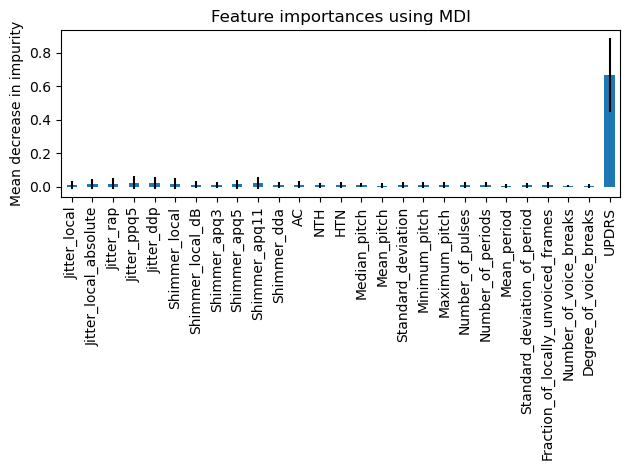

In [47]:
import pandas as pd

forest_importances = pd.Series(importances, index=feature_names)

fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=std, ax=ax)
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

In [40]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    forest, X_test, Y_test, n_repeats=10, random_state=42, n_jobs=2
)

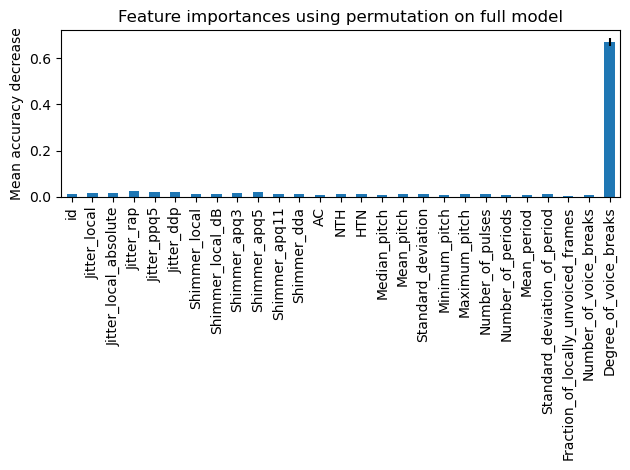

In [41]:
fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=result.importances_std, ax=ax)
ax.set_title("Feature importances using permutation on full model")
ax.set_ylabel("Mean accuracy decrease")
fig.tight_layout()
plt.show()

In [22]:
dtree = DecisionTreeClassifier()
dtree.fit(X_train, Y_train)

DecisionTreeClassifier()

In [23]:
importances = dtree.feature_importances_

In [31]:
std = np.std([tree.feature_importances_ for tree in forest.estimators_], axis=0)

AttributeError: 'DecisionTreeClassifier' object has no attribute 'estimators_'

NameError: name 'std' is not defined

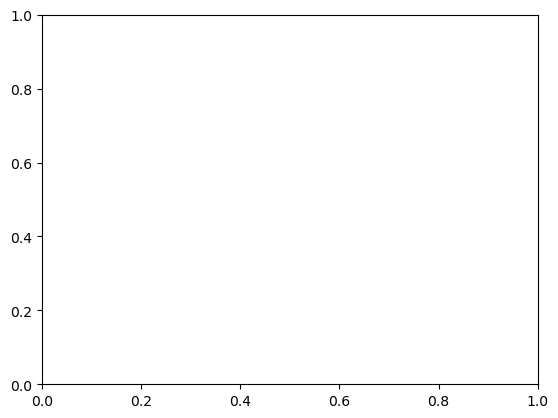

In [30]:
forest_importances = pd.Series(importances, index=names[:27])

fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=std, ax=ax)
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

In [21]:
# evaluate each algorithm / model
results = []
names = []
print("Scores for each algorithm:")
for name, model in models:
    kfold = model_selection.KFold(n_splits = num_folds)
    cv_results = model_selection.cross_val_score(model, X_train, Y_train, cv = kfold, scoring = scoring)
    results.append(cv_results)
    names.append(name)
    model.fit(X_train, Y_train)
    predictions = model.predict(X_test)
    print(name, accuracy_score(Y_test, predictions)*100)
    print(matthews_corrcoef(Y_test, predictions))
    print()

Scores for each algorithm:
LR 98.15950920245399
0.9626524263309272



/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:444: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:444: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#log

LDA 89.77505112474438
0.799763148796273

KNN 81.39059304703477
0.617541591662018

DT 100.0
1.0



/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:559: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:559: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:559: ConvergenceWarning: lbfgs failed to converge (status=

NN 97.13701431492842
0.94175327901461

NB 85.88957055214725
0.7251806098293447

GB 100.0
1.0

